# LeetCode #138: Copy List with Random Pointer

https://leetcode.com/problems/copy-list-with-random-pointer/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Hash Map: old node → new node ★** | $O(n)$ | $O(n)$ |
| **Interleaving Nodes** | $O(n)$ | $O(1)$ |

`n` is the number of nodes. $O(n)$ time means each node is handled a fixed number of times: a
1,000-node list takes a few thousand steps. The copies themselves always take $n$ new nodes; the
space column counts what's needed *on top of* them. $O(n)$ there means a lookup table with one entry
per node; $O(1)$ means a few pointer variables.

Each node has the usual `next` pointer plus a `random` pointer that can point at **any** node in the
list, or at nothing. A **deep copy** means brand-new nodes with the same shape: every `next` and
`random` in the copy must point at copied nodes, never back into the original.

---

## Understanding the Methods

### Hash Map: old node → new node ★ (the one coded below)
First pass: make a bare copy of every node and record "this original goes with that copy" in a hash
map (a lookup table keyed by the node itself). Second pass: for each original, look up its copy and
wire the copy's `next` and `random` by looking up the copies of the original's `next` and `random`.
Two passes, because a `random` can point *forward* to a node that hasn't been copied yet.

### Interleaving Nodes
Avoids the map by storing each copy right after its original (`A → A' → B → B'`), so "the copy of X"
is always `X.next`. Then `copy.random = original.random.next`, and a final pass unzips the two lists.
It needs no table, but it temporarily rewires the input, and the unzip step is easy to get wrong.

**Why the hash map is the pick here:** both are linear time. The map version expresses the idea in
two simple loops and never touches the original list; reach for interleaving when the extra table is
genuinely too much memory.

**Constraints:**
* `0 <= n <= 1000`
* `-10^4 <= Node.val <= 10^4`
* `Node.random` is `null` or points to some node in the linked list

## Explain Like I'm a Newbie

### What the question is actually asking

Each node has a value, a `next` arrow, and a second arrow, `random`, that can point anywhere in the
list: backwards, forwards, at itself, or at nothing. Build a completely separate copy with the same
values and the same arrow pattern.

```
original:  7 -> 13 -> 11 -> 10 -> 1         random:  13->7, 11->1, 10->11, 1->7
copy:      7'-> 13'-> 11'-> 10'-> 1'        random:  13'->7', 11'->1', 10'->11', 1'->7'
```

The copy's arrows must point at **copies**. If `13'.random` points at the original 7, you've built
something that looks right and isn't a copy at all.

### The one idea you need: a lookup table from "original" to "its copy"

Copying values and `next` is easy: walk the list and make new nodes. The `random` arrows are the
problem. When you copy 11, its random target 1 might not have been copied yet, and even if it has,
how do you find *that* copy?

So split the job in two. First walk the list making a bare copy of every node, and write each pair
into a table: original node in, copy out. Then walk again. Now every copy exists, so for any original
arrow `A -> B`, the copy's arrow is "copy of A" to "copy of B": two lookups.

### What that means in code

The table is a **hash map** (`dict` in Python, `Dictionary` in C#), keyed by the node object itself.

1. Pass 1: `map[cur] = Node(cur.val)` for every node.
2. Pass 2: `map[cur].next = map[cur.next]` and `map[cur].random = map[cur.random]`, skipping the
   ones that are null.
3. Return `map[head]`.

### Mistakes people make the first time

1. **Copying `random` straight across.** `copy.random = cur.random` points into the original list.
   Print each node as `[value, random index]` and every LeetCode sample comes out exactly right,
   because the shape is right. LeetCode's checker rejects it; your own print statement won't.
2. **Keying the map by value.** The third sample is three nodes that are all `3`. Keyed by value,
   they collapse into one entry.
3. **Doing it in one pass.** When a `random` points forward, its target has no copy yet.

### Things worth knowing

The table costs one entry per node on top of the copies. The interleaving trick in the header avoids
it, at the price of temporarily rewiring the input list.

## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "Copying `next` is easy; `random` is the problem, because it can point at a node I haven't copied yet. So two passes with a map from each original node to its copy: first make all the copies, then wire every copy's `next` and `random` through the map. O(n) time, O(n) for the map. If the map's too much memory, there's an interleaving trick that drops it to O(1), at the cost of temporarily rewiring your list."

---

### I slide the problem across the table

`[[7,null],[13,0],[11,4],[10,2],[1,0]]`: each pair is a value and the index the `random` pointer targets. Return a deep copy.

> **You:** "So I build new nodes, same values, same `next` chain, and each copy's `random` points at the copy of whatever the original's `random` pointed at. No pointer in my result is allowed to land in your list."

That last sentence is what I want to hear restated, because it's the whole difficulty. Then the clarifier:

> **You:** "Can values repeat?"

**"Yes."** That's the question I'm listening for. It tells you that you can't identify a node by its value, so whatever you look things up by has to be the node itself. "Is the list sorted?" or "can values be negative?" doesn't change anything here.

> **You:** "And can I modify the input temporarily, as long as it's restored?"

**"I'd rather you didn't."** Good: you've seen that the O(1) approach exists and what it costs, and now you know which one I want.

---

### Now tell me what's actually hard about it

"I'll use a hash map" is a data structure, not an insight. Why do you need one?

> **You:** "If it were just `next`, I'd walk the list making nodes and link each to the previous one. The `random` pointer breaks that. When I'm copying node 11, its random points at node 1, which is further on and doesn't have a copy yet. And even for a random that points backwards, I'd need a way to get from 'the original node 7' to 'my copy of node 7', and nodes don't carry that."

Then:

> **You:** "So I need a translation table, original to copy, and every copy has to exist before I wire anything. That's two passes: create, then connect."

That's the insight. The map falls out of "I need to translate pointers", and the two passes fall out of "random can point forward".

---

### Before you touch the board, tell me the shape and the cost

> **You:** "First loop: for every node, `map[node] = Node(node.val)`. Second loop: for every node, set `map[node].next` to `map[node.next]` and `map[node].random` to `map[node.random]`, guarding the nulls. Return `map[head]`."

> **You:** "Each loop visits each node once and does constant-time map operations, so O(n). The map holds n entries, so O(n) extra on top of the n copies I have to build anyway."

---

### Now whiteboard it

```
if not head: return None
node_map = {}
cur = head
while cur:
    node_map[cur] = Node(cur.val)
    cur = cur.next
```

> **You:** "Keyed by the node object, not its value: you said values repeat, and the third sample is three nodes that are all 3."

If you key by value, I'll point at that sample. If you don't say why it's keyed by node, I'll ask.

```
cur = head
while cur:
    if cur.next:   node_map[cur].next = node_map[cur.next]
    if cur.random: node_map[cur].random = node_map[cur.random]
    cur = cur.next
return node_map[head]
```

> **You:** "Both pointers go through the map. If I wrote `copy.random = cur.random`, the output would print exactly right, values and random indices, and still be wrong, because those arrows point into your list."

That sentence is the one I'm really waiting for. The shallow-random bug passes any test that prints the shape, and I want to know you'd catch it without a judge telling you.

If there's time, I'll ask about the two `if` guards. The answer I like: looking up a null key fails outright (a `KeyError` in Python, an exception in C#), so the guards are required, not tidiness. A neat alternative is to seed the map with `None → None` before the loops. Then both lookups work unguarded, and a null pointer in the original simply becomes a null pointer in the copy.

---

### Walk me through it before you say you're done

> **You:** "LeetCode's first example. Pass one makes 7', 13', 11', 10', 1' and records the pairs. Pass two, at 7: next is 13, so 7'.next = 13'; random is null, skip. At 13: next 11'; random is node 7, the map says 7', so 13'.random = 7'. At 11: random is node 1, which pass one already copied, so 11'.random = 1'. That's the forward-pointing case working. 10 goes to 11', and 1 goes to 7'. Return 7'."

> **You:** "And the empty list returns null before the map is made. A node whose random points at itself, `[[1,0]]`, gets `map[node].random = map[node]`, its own copy, not the original."

---

### Then tell me what it costs, before I ask

The time is optimal, so the useful thing to volunteer is the trade-off:

> **You:** "The map is n entries. If memory mattered, I'd interleave instead: put each copy right after its original, so the copy of any node X is just `X.next`. Then `X.next.random = X.random.next`, and a final pass unzips the two lists. O(1) extra space, but it mutates your list while it runs, which you said you'd rather avoid, and if anything throws halfway through, your list is left scrambled."

That's exactly the kind of trade-off conversation I want at the end: two correct answers and a reason to pick one.

---

### What would worry me

Copying `random` directly and calling it done because the printed output matched. A map keyed by value. Trying to do it in one pass and patching forward pointers with special cases. And reaching for interleaving first, getting the unzip wrong, and running out of time without a working answer when the two-loop version was available.

## Solutions

The C#, Python and Go versions are the same two loops: make every copy, then wire every copy's `next` and `random` through the map. The comments mark why it's two passes and why the map is keyed by node.

### C#

In [ ]:
// HashMap O(n) time, O(n) space
public class Node {
    public int val;
    public Node next;
    public Node random;
    public Node(int _val) { val = _val; }
}

public class Solution {
    public Node CopyRandomList(Node head) {
        if (head == null) return null;
        // original node -> its copy. Keyed by the node itself: values can repeat.
        var map = new Dictionary<Node, Node>();
        var cur = head;
        // Pass 1: make every copy first. A random pointer can point FORWARD,
        // so its target's copy has to exist before any wiring starts.
        while (cur != null) { map[cur] = new Node(cur.val); cur = cur.next; }
        cur = head;
        // Pass 2: translate both pointers through the map. Copying cur.random
        // directly would point the copy back into the ORIGINAL list.
        while (cur != null) {
            if (cur.next != null) map[cur].next = map[cur.next];
            if (cur.random != null) map[cur].random = map[cur.random];
            cur = cur.next;
        }
        return map[head];
    }
}

### Python

Python's `dict` can use the node objects themselves as keys: a class without its own `__eq__` and `__hash__` is compared by identity, so two nodes with the same value are still two different keys.

In [ ]:
# HashMap O(n) time, O(n) space
class Node:
    def __init__(self, x, next=None, random=None):
        self.val = x
        self.next = next
        self.random = random

class Solution:
    def copyRandomList(self, head: 'Optional[Node]') -> 'Optional[Node]':
        if not head: return None
        # original node -> its copy. Keyed by the node itself: values can repeat.
        node_map = {}
        cur = head
        # Pass 1: make every copy first. A random pointer can point FORWARD,
        # so its target's copy has to exist before any wiring starts.
        while cur:
            node_map[cur] = Node(cur.val)
            cur = cur.next
        cur = head
        # Pass 2: translate both pointers through the map. Copying cur.random
        # directly would point the copy back into the ORIGINAL list.
        while cur:
            if cur.next: node_map[cur].next = node_map[cur.next]
            if cur.random: node_map[cur].random = node_map[cur.random]
            cur = cur.next
        return node_map[head]

### Go

The map is keyed by `*Node`, a pointer, so lookups go by which node it is, not by its value.

In [ ]:
// HashMap O(n) time, O(n) space
type Node struct {
    Val int
    Next *Node
    Random *Node
}

func copyRandomList(head *Node) *Node {
    if head == nil { return nil }
    // original node -> its copy. Keyed by pointer: values can repeat.
    nodeMap := make(map[*Node]*Node)
    // Pass 1: make every copy first. A random pointer can point FORWARD,
    // so its target's copy has to exist before any wiring starts.
    for cur := head; cur != nil; cur = cur.Next {
        nodeMap[cur] = &Node{Val: cur.Val}
    }
    // Pass 2: translate both pointers through the map. Copying cur.Random
    // directly would point the copy back into the ORIGINAL list.
    for cur := head; cur != nil; cur = cur.Next {
        if cur.Next != nil { nodeMap[cur].Next = nodeMap[cur.Next] }
        if cur.Random != nil { nodeMap[cur].Random = nodeMap[cur.Random] }
    }
    return nodeMap[head]
}

### Rust

There's no Rust solution here: the cell only sketches a node type. A list where any node can point at any other doesn't fit Rust's one-owner `Box` model, so a working version needs shared ownership (`Rc<RefCell<Node>>`) or raw pointers and `unsafe`. Use the Python version as the reference.

In [ ]:
// No Rust solution: this cell only sketches a node type (see the note above).
// A node that any other node can point at needs shared ownership, which Box
// can't express; typically solved with Rc<RefCell<Node>> or unsafe pointers.
use std::collections::HashMap;

pub struct Node { pub val: i32, pub next: Option<Box<Node>>, pub random: *mut Node }

impl Node {
    pub fn new(val: i32) -> Self {
        Node { val, next: None, random: std::ptr::null_mut() }
    }
}

## Example Scenarios

### 1. Common Case — Random Pointers Across the List
**Input:** `head = [[7,null],[13,0],[11,4],[10,2],[1,0]]`

Each pair is a value and the index its `random` points to. Pass one makes five bare copies; pass two
wires them, and 11's random, which points *forward* to the last node, works because that copy
already exists. **Output:** `[[7,null],[13,0],[11,4],[10,2],[1,0]]`, built from new nodes

### 2. Slightly Complex — Two Randoms, One Target
**Input:** `head = [[1,1],[2,1]]`

Both randoms point at the second node, including the second node's own. Through the map, both copies
point at the *copy* of the second node, so the copy has the same shared target.
**Output:** `[[1,1],[2,1]]`, built from new nodes

### 3. Edge Case: Time Factor — Single Node, No Random
**Input:** `head = [[3,null]]`

Not a slow input: every node costs the same two visits, so the real worst case is simply the
longest list, 1,000 nodes. Here it's one copy, one null random skipped. **Output:** `[[3,null]]`

### 4. Edge Case: Space Factor — Self-Referential Random
**Input:** `head = [[1,0]]`

Memory is always one copy plus one map entry per node, so the true worst case is again the longest
list. This one tests the self-loop: the map turns "points at itself" into "the copy points at the
copy", never at the original. **Output:** `[[1,0]]`, built from a new node

### 5. Almost-Impossible but Plausible — Empty List
**Input:** `head = []`

Nothing to copy. The function returns null before it builds the map. **Output:** `[]`

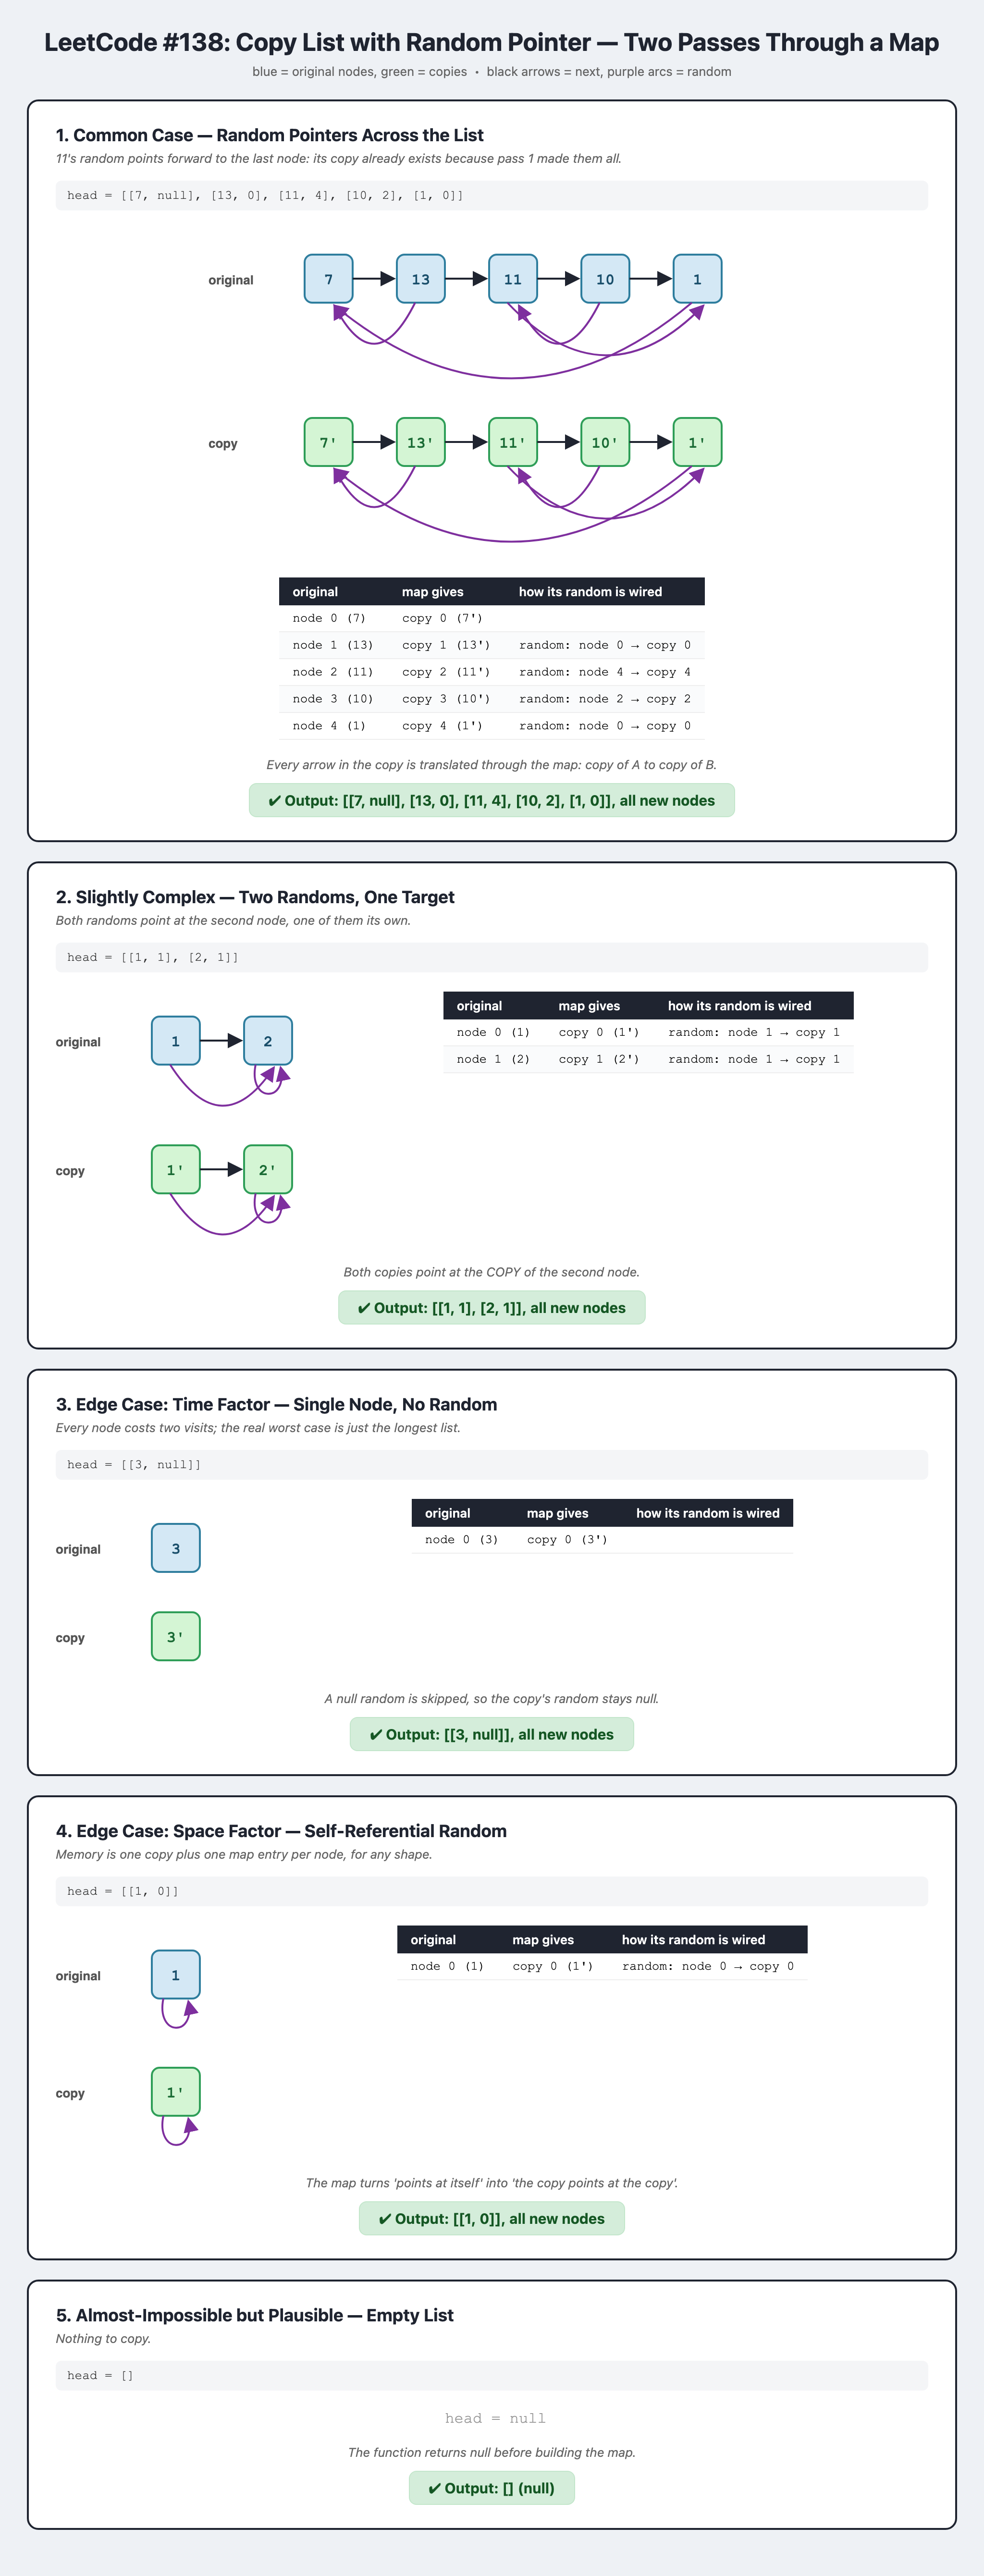

## Watch It Run

*Watch pass 2 reach 11: its random points forward to the last node, and it works only because pass 1 already made every copy and wrote it in the map.*

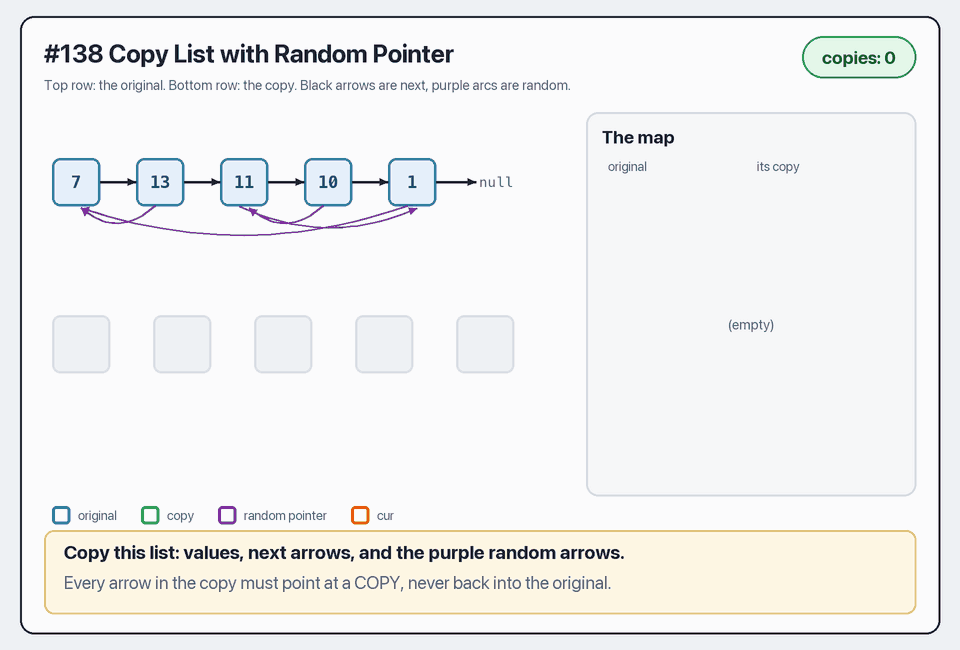

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0138.html)**